## General election analysis

**Goal:** Determine the extent to which young voters (especially those with a college degree) exceeded turnout expectations in the 2026 general election in Michigan and what other demographic factors played a role in widening El-Sayed's margins over Elissa Slotkin's narrow victory in 2024.

In [9]:
#imports
import pandas as pd
df = pd.read_csv('data/vote_swing_plus_demos_for_analysis.csv')
df.columns = ['county', 'ballots_cast', 'registered_voters', 'turnout_perc',
       'population', 'sex_ratio', 'median_age', '20_34_population_share',
       'white_share', 'non_white_share', 'black_share', 'asian_share',
       'hispanic_share', 'less_than_hs_share',
       'less_than_hs_earnings', 'hs_grad_share',
       'hs_grad_median earnings',
       'some_college_share',
       'some_college_earnings', 'bach_deg_share', 'bach_earnings',
       'grad_deg_share',
       'grad_earnings',
       'coll_earnings_premium', 'hs_plus_share', 'bach_plus_share',
       'age_quart', 'non_white_quart', 'ed_quart',
       'el_sayed_share', 'slotkin_share', 'harris_share',
       'swing_from_harris', 'swing_from_slotkin']

### Question 1: did younger voters drive turnout?

In [10]:
#voter turnout by age quartile
for quart in ["1st", "2nd", "3rd", "4th"]:
    print(quart, " quartile, median age")
    print(df[df['age_quart'] == quart]["turnout_perc"].mean())

1st  quartile, median age
0.5625
2nd  quartile, median age
0.5595000000000001
3rd  quartile, median age
0.56
4th  quartile, median age
0.5794117647058823


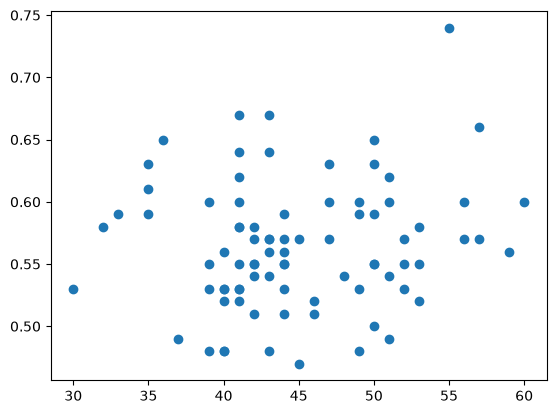

In [12]:
#voter turnout vs. median age in each county
import matplotlib.pyplot as plt
plt.scatter(df["median_age"], df["turnout_perc"])

**Result:** There doesn't appear to be a clear relationship between age and turnout across counties. This doesn't mean that within the same county, younger people exceeded expectations for turnout.

### Question 2: did more highly educated younger voters turnout more than others?

**Across all counties, there is a clear relationship between turnout and the % of the population with a bachelor's degree.**

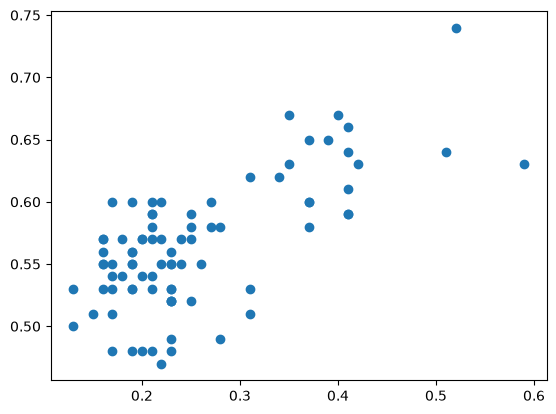

In [13]:
#Overall education vs. voter turnout
plt.scatter(df["bach_plus_share"], df["turnout_perc"])

**But does education differentiate between counties with similar median ages?**

In [ ]:
for age_quart in ["1st", "2nd", "3rd", "4th"]:
    for ed_quart in ["1st", "2nd", "3rd", "4th"]:
        print(age_quart, " age quartile // ", ed_quart, " education quartile")
        print(
            df[(df['age_quart'] == age_quart) & 
                (df['ed_quart'] == ed_quart)]["turnout_perc"].mean())

**The pattern holds within all age quartiles**

### Question 3: Which variables have the greatest impact on turnout?

In [ ]:
import numpy as np

# Multi-variable regression with turnout_perc as the target
import statsmodels.api as sm

# Use a set of demographic / county-level predictors (exclude target and obvious post-outcome variables)
feature_cols = [
    "population",
    "sex_ratio",
    "median_age",
    "20_34_population_share",
    "non_white_share",
    "hispanic_share",
    "bach_plus_share",
    "coll_earnings_premium",
    "bach_earnings",
]

# Keep only rows with complete data for the selected features and target
reg_df = df[feature_cols + ["turnout_perc"]].dropna()

X = reg_df[feature_cols]
y = reg_df["turnout_perc"]

# Add intercept
X = sm.add_constant(X)

# Fit OLS model
model = sm.OLS(y, X).fit()

# Display results
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           turnout_perc   R-squared:                       0.642
Model:                            OLS   Adj. R-squared:                  0.603
Method:                 Least Squares   F-statistic:                     16.60
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           8.37e-14
Time:                        16:21:16   Log-Likelihood:                 172.08
No. Observations:                  83   AIC:                            -326.2
Df Residuals:                      74   BIC:                            -304.4
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                      0

**Here's a more rigorous regression analysis**

Missing values before complete-case filtering:
Series([], dtype: int64)

Rows before filtering: 83
Rows used in regression: 83
Rows excluded: 0

Outcome distribution:
count    83.000000
mean      0.564699
std       0.051189
min       0.470000
25%       0.530000
50%       0.560000
75%       0.595000
max       0.740000
Name: turnout_perc, dtype: float64


CONVENTIONAL OLS RESULTS
                            OLS Regression Results                            
Dep. Variable:           turnout_perc   R-squared:                       0.698
Model:                            OLS   Adj. R-squared:                  0.661
Method:                 Least Squares   F-statistic:                     18.73
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           9.90e-16
Time:                        16:15:14   Log-Likelihood:                 179.08
No. Observations:                  83   AIC:                            -338.2
Df Residuals:                      73   BIC:                      

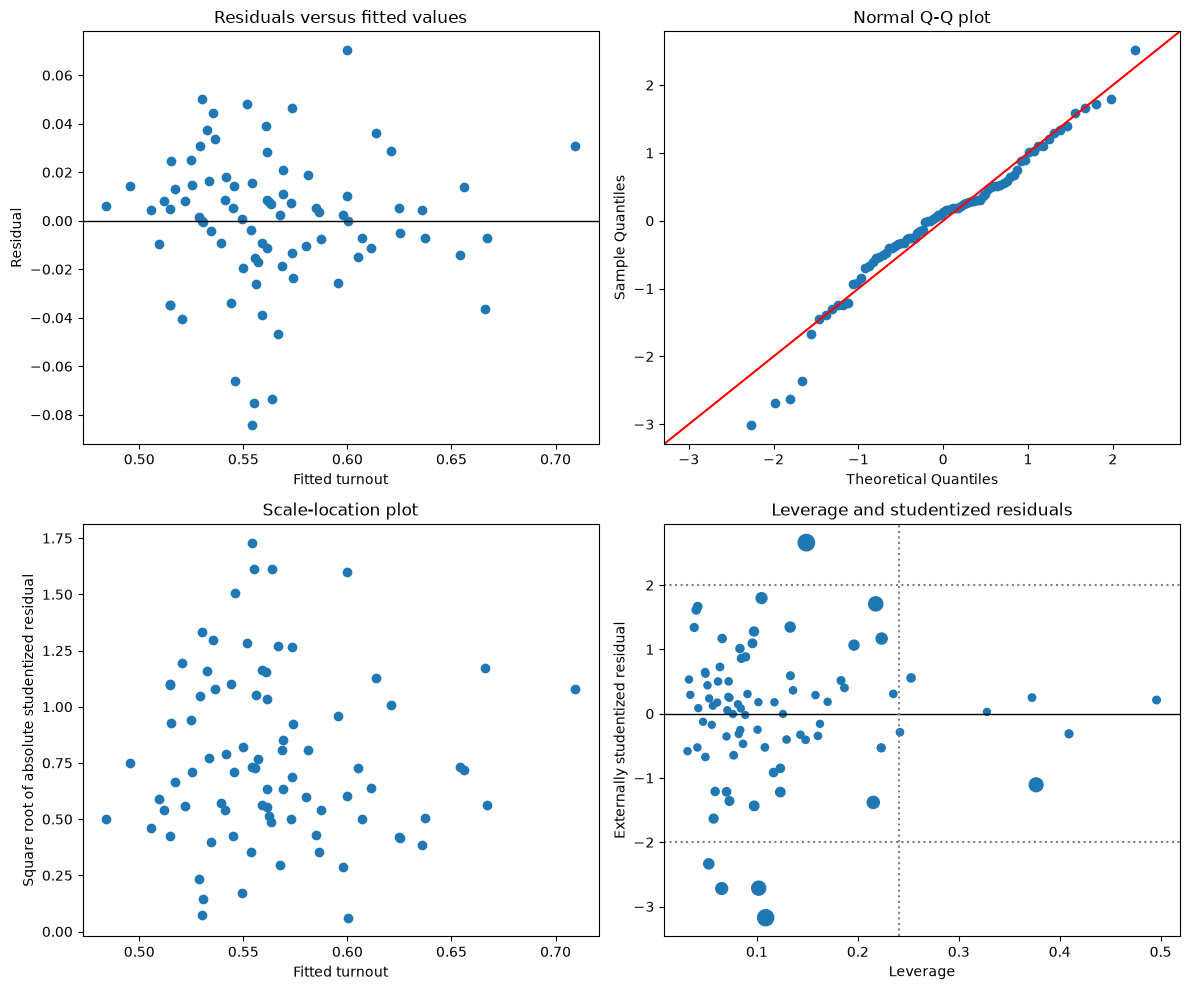


REDUCED MODEL WITH HC3 STANDARD ERRORS
                            OLS Regression Results                            
Dep. Variable:           turnout_perc   R-squared:                       0.678
Model:                            OLS   Adj. R-squared:                  0.648
Method:                 Least Squares   F-statistic:                     31.50
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           6.65e-20
Time:                        16:15:14   Log-Likelihood:                 176.51
No. Observations:                  83   AIC:                            -337.0
Df Residuals:                      75   BIC:                            -317.7
Df Model:                           7                                         
Covariance Type:                  HC3                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from scipy import stats
from statsmodels.stats.diagnostic import (
    het_breuschpagan,
    het_white,
    linear_reset
)
from statsmodels.stats.outliers_influence import (
    variance_inflation_factor,
    OLSInfluence
)

# ---------------------------------------------------------
# 1. Define outcome and predictors
# ---------------------------------------------------------

target_col = "turnout_perc"

feature_cols = [
    "population",
    "sex_ratio",
    "median_age",
    "20_34_population_share",
    "non_white_share",
    "hispanic_share",
    "bach_plus_share",
    "coll_earnings_premium",
    "bach_earnings",
]

# Keep an identifier if one exists.
# Change "county" to the appropriate column name in your data.
id_col = "county" if "county" in df.columns else None

model_cols = feature_cols + [target_col]
if id_col:
    model_cols.append(id_col)

reg_df = df[model_cols].copy()

# Force model variables to numeric.
for col in feature_cols + [target_col]:
    reg_df[col] = pd.to_numeric(reg_df[col], errors="coerce")

# Replace infinite values before dropping missing observations.
reg_df = reg_df.replace([np.inf, -np.inf], np.nan)

missing_summary = (
    reg_df[feature_cols + [target_col]]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print("Missing values before complete-case filtering:")
print(missing_summary[missing_summary > 0])
print()

original_n = len(reg_df)
reg_df = reg_df.dropna(subset=feature_cols + [target_col]).copy()

print(f"Rows before filtering: {original_n}")
print(f"Rows used in regression: {len(reg_df)}")
print(f"Rows excluded: {original_n - len(reg_df)}")
print()

# ---------------------------------------------------------
# 2. Basic range and coding checks
# ---------------------------------------------------------

print("Outcome distribution:")
print(reg_df[target_col].describe())
print()

if not reg_df[target_col].between(0, 1).all():
    print(
        "WARNING: turnout_perc contains values outside 0 to 1. "
        "If turnout is recorded from 0 to 100, divide it by 100 "
        "before using the fractional-response model below."
    )

share_cols = [
    "20_34_population_share",
    "non_white_share",
    "hispanic_share",
    "bach_plus_share",
]

for col in share_cols:
    outside_range = ~reg_df[col].between(0, 1)

    if outside_range.any():
        print(
            f"WARNING: {col} has {outside_range.sum()} values outside 0 to 1. "
            "Check whether the variable is expressed as a percentage from "
            "0 to 100 instead of a proportion from 0 to 1."
        )

# Check variables with no variation.
zero_variance_cols = [
    col for col in feature_cols
    if reg_df[col].nunique(dropna=True) <= 1
]

if zero_variance_cols:
    raise ValueError(
        "These predictors have no variation and cannot be estimated: "
        f"{zero_variance_cols}"
    )

# ---------------------------------------------------------
# 3. Transform strongly scaled variables
# ---------------------------------------------------------

# Population is often highly right-skewed. A log transformation usually
# produces a more meaningful county-level comparison than raw population.
if (reg_df["population"] <= 0).any():
    raise ValueError("Population must be positive to calculate log_population.")

reg_df["log_population"] = np.log(reg_df["population"])

# Express earnings in $10,000 units so coefficients are easier to read.
reg_df["bach_earnings_10k"] = reg_df["bach_earnings"] / 10_000
reg_df["coll_earnings_premium_10k"] = (
    reg_df["coll_earnings_premium"] / 10_000
)

transformed_features = [
    "log_population",
    "sex_ratio",
    "median_age",
    "20_34_population_share",
    "non_white_share",
    "hispanic_share",
    "bach_plus_share",
    "coll_earnings_premium_10k",
    "bach_earnings_10k",
]

X = sm.add_constant(
    reg_df[transformed_features],
    has_constant="add"
)
y = reg_df[target_col]

# ---------------------------------------------------------
# 4. Fit OLS with conventional and HC3 robust errors
# ---------------------------------------------------------

ols_model = sm.OLS(y, X).fit()

# HC3 is generally a good choice for a modest sample and influential
# observations. Coefficients remain the same, but standard errors,
# confidence intervals and p-values can change.
ols_hc3 = ols_model.get_robustcov_results(cov_type="HC3")

print("\nCONVENTIONAL OLS RESULTS")
print(ols_model.summary())

print("\nOLS RESULTS WITH HC3 ROBUST STANDARD ERRORS")
print(ols_hc3.summary())

# Create a cleaner coefficient table.
hc3_results = pd.DataFrame({
    "variable": X.columns,
    "coefficient": ols_hc3.params,
    "robust_std_error": ols_hc3.bse,
    "t_statistic": ols_hc3.tvalues,
    "p_value": ols_hc3.pvalues,
    "ci_95_low": ols_hc3.conf_int()[:, 0],
    "ci_95_high": ols_hc3.conf_int()[:, 1],
})

print("\nHC3 COEFFICIENT TABLE")
print(hc3_results.to_string(index=False))

# ---------------------------------------------------------
# 5. Check multicollinearity
# ---------------------------------------------------------

vif_df = pd.DataFrame({
    "variable": X.columns,
    "VIF": [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ],
})

# The intercept VIF is not substantively useful.
vif_df = vif_df[vif_df["variable"] != "const"]
vif_df = vif_df.sort_values("VIF", ascending=False)

print("\nVARIANCE INFLATION FACTORS")
print(vif_df.to_string(index=False))

print("\nPredictor correlations:")
print(
    reg_df[transformed_features]
    .corr()
    .round(3)
    .to_string()
)

# ---------------------------------------------------------
# 6. Residual and specification tests
# ---------------------------------------------------------

residuals = ols_model.resid
fitted = ols_model.fittedvalues

bp_stat, bp_pvalue, bp_fstat, bp_f_pvalue = het_breuschpagan(
    residuals,
    ols_model.model.exog
)

white_stat, white_pvalue, white_fstat, white_f_pvalue = het_white(
    residuals,
    ols_model.model.exog
)

reset_result = linear_reset(
    ols_model,
    power=2,
    use_f=True
)

shapiro_stat, shapiro_pvalue = stats.shapiro(residuals)

diagnostic_tests = pd.DataFrame({
    "test": [
        "Breusch-Pagan heteroskedasticity test",
        "White heteroskedasticity test",
        "Ramsey RESET specification test",
        "Shapiro-Wilk residual normality test",
    ],
    "statistic": [
        bp_stat,
        white_stat,
        float(reset_result.fvalue),
        shapiro_stat,
    ],
    "p_value": [
        bp_pvalue,
        white_pvalue,
        float(reset_result.pvalue),
        shapiro_pvalue,
    ],
})

print("\nDIAGNOSTIC TESTS")
print(diagnostic_tests.to_string(index=False))

# ---------------------------------------------------------
# 7. Identify influential observations
# ---------------------------------------------------------

influence = OLSInfluence(ols_model)

influence_df = pd.DataFrame({
    "row_index": reg_df.index,
    "fitted_turnout": fitted,
    "residual": residuals,
    "studentized_residual": influence.resid_studentized_external,
    "leverage": influence.hat_matrix_diag,
    "cooks_distance": influence.cooks_distance[0],
    "dffits": influence.dffits[0],
})

if id_col:
    influence_df.insert(
        1,
        id_col,
        reg_df[id_col].values
    )

n = len(reg_df)
number_of_parameters = int(ols_model.df_model) + 1

# Common screening thresholds, not automatic deletion rules.
cooks_threshold = 4 / n
leverage_threshold = 2 * number_of_parameters / n
studentized_threshold = 2

influence_df["high_cooks_distance"] = (
    influence_df["cooks_distance"] > cooks_threshold
)
influence_df["high_leverage"] = (
    influence_df["leverage"] > leverage_threshold
)
influence_df["large_studentized_residual"] = (
    influence_df["studentized_residual"].abs() > studentized_threshold
)

influence_df["flagged"] = influence_df[
    [
        "high_cooks_distance",
        "high_leverage",
        "large_studentized_residual",
    ]
].any(axis=1)

print(f"\nCook's distance screening threshold: {cooks_threshold:.4f}")
print(f"Leverage screening threshold: {leverage_threshold:.4f}")

print("\nMOST INFLUENTIAL OBSERVATIONS")
print(
    influence_df
    .sort_values("cooks_distance", ascending=False)
    .head(10)
    .to_string(index=False)
)

# ---------------------------------------------------------
# 8. Diagnostic plots
# ---------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Residuals versus fitted
axes[0, 0].scatter(fitted, residuals)
axes[0, 0].axhline(0, color="black", linewidth=1)
axes[0, 0].set_title("Residuals versus fitted values")
axes[0, 0].set_xlabel("Fitted turnout")
axes[0, 0].set_ylabel("Residual")

# Q-Q plot
sm.qqplot(
    residuals,
    line="45",
    fit=True,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Normal Q-Q plot")

# Scale-location plot
sqrt_abs_studentized = np.sqrt(
    np.abs(influence.resid_studentized_internal)
)
axes[1, 0].scatter(fitted, sqrt_abs_studentized)
axes[1, 0].set_title("Scale-location plot")
axes[1, 0].set_xlabel("Fitted turnout")
axes[1, 0].set_ylabel("Square root of absolute studentized residual")

# Leverage versus studentized residual
axes[1, 1].scatter(
    influence.hat_matrix_diag,
    influence.resid_studentized_external,
    s=25 + 1000 * influence.cooks_distance[0]
)
axes[1, 1].axhline(0, color="black", linewidth=1)
axes[1, 1].axhline(2, color="gray", linestyle=":")
axes[1, 1].axhline(-2, color="gray", linestyle=":")
axes[1, 1].axvline(
    leverage_threshold,
    color="gray",
    linestyle=":"
)
axes[1, 1].set_title("Leverage and studentized residuals")
axes[1, 1].set_xlabel("Leverage")
axes[1, 1].set_ylabel("Externally studentized residual")

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 9. Sensitivity model with potentially redundant predictors removed
# ---------------------------------------------------------

# Potential overlap:
# 1. median_age and 20_34_population_share both measure age structure.
# 2. coll_earnings_premium may be derived partly from bach_earnings.
# 3. non_white_share and hispanic_share may overlap depending on coding.

reduced_features = [
    "log_population",
    "sex_ratio",
    "median_age",
    "non_white_share",
    "hispanic_share",
    "bach_plus_share",
    "bach_earnings_10k",
]

X_reduced = sm.add_constant(
    reg_df[reduced_features],
    has_constant="add"
)

reduced_model = sm.OLS(y, X_reduced).fit()
reduced_hc3 = reduced_model.get_robustcov_results(cov_type="HC3")

print("\nREDUCED MODEL WITH HC3 STANDARD ERRORS")
print(reduced_hc3.summary())

comparison = pd.DataFrame({
    "model": [
        "Full model",
        "Reduced model",
    ],
    "observations": [
        int(ols_model.nobs),
        int(reduced_model.nobs),
    ],
    "r_squared": [
        ols_model.rsquared,
        reduced_model.rsquared,
    ],
    "adjusted_r_squared": [
        ols_model.rsquared_adj,
        reduced_model.rsquared_adj,
    ],
    "AIC": [
        ols_model.aic,
        reduced_model.aic,
    ],
    "BIC": [
        ols_model.bic,
        reduced_model.bic,
    ],
})

print("\nMODEL COMPARISON")
print(comparison.to_string(index=False))

**The more robust model also comes up with similar results:** the variables that most strongly influence turnout are: 
 1. Education: a 10 percentage-point increase in the share of population with a bachelor's degree or higher was associated with a 4.5-point increase in turnout.
 2. Non-white share: a 10 percentage point increase in the share of population that isn't white was associated with a 2.3-point decline in turnout.
 3. Median age: a 5-year increase in the median age was associated with a 1.7-point increase in voter turnout.

**Let's look at support for El-Sayed specifically.**

### Question 4: Did having more young voters make a county more likely to swing towards El-Sayed?

In [20]:
print("Swing from Slotkin to El-Sayed")
print("-----------------------------")
for quart in ["1st", "2nd", "3rd", "4th"]:
    print(quart, " quartile, median age")
    print(df[df['age_quart'] == quart]["swing_from_slotkin"].mean())

print()
print("Swing from Harris to El-Sayed")
print("-----------------------------")
for quart in ["1st", "2nd", "3rd", "4th"]:
    print(quart, " quartile, median age")
    print(df[df['age_quart'] == quart]["swing_from_harris"].mean())

Swing from Slotkin to El-Sayed
-----------------------------
1st  quartile, median age
6.078571428571428
2nd  quartile, median age
4.62
3rd  quartile, median age
4.800000000000001
4th  quartile, median age
3.476470588235294

Swing from Harris to El-Sayed
-----------------------------
1st  quartile, median age
7.632142857142857
2nd  quartile, median age
6.494999999999999
3rd  quartile, median age
6.127777777777777
4th  quartile, median age
5.029411764705882


**Counties in the youngest quartile swung 6 points towards El-Sayed from Elissa Slotkin in 2024 and 7.6 points from Harris, compared to 3.5 points from Slotkin and 5 points from Harris in the oldest quartile.**

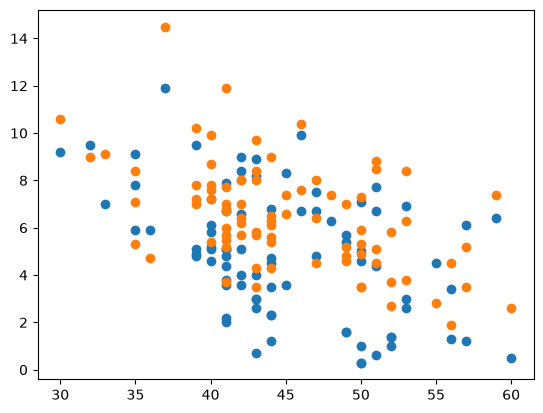

In [22]:
#scatter plot
plt.scatter(df["median_age"], df['swing_from_slotkin'])
plt.scatter(df["median_age"], df['swing_from_harris'])

### Question 5: Was age the biggest factor in the swing towards El-Sayed?

**Back to the regression models...**

In [28]:
import numpy as np
import statsmodels.api as sm

# ---------------------------------------------------------
# Multivariable regression:
# Target = swing toward El-Sayed compared with Slotkin
# ---------------------------------------------------------

target_col = "swing_from_slotkin"

feature_cols = [
    "population",
    "sex_ratio",
    "median_age",
    "20_34_population_share",
    "non_white_share",
    "hispanic_share",
    "bach_plus_share",
    "coll_earnings_premium",
    "bach_earnings",
]

# Keep only rows with complete data
reg_df = df[feature_cols + [target_col]].dropna().copy()

# Log-transform population because county populations are
# highly skewed and raw population is on a very different scale
reg_df["log_population"] = np.log(reg_df["population"])

# Predictors used in the regression
model_features = [
    "log_population",
    "sex_ratio",
    "median_age",
    "non_white_share",
    "hispanic_share",
    "bach_plus_share",
    "bach_earnings",
]

X = reg_df[model_features]
y = reg_df[target_col]

# Add intercept
X = sm.add_constant(X)

# Fit OLS with HC3 robust standard errors
model = sm.OLS(y, X).fit(cov_type="HC3")

# Display results
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:     swing_from_slotkin   R-squared:                       0.307
Model:                            OLS   Adj. R-squared:                  0.242
Method:                 Least Squares   F-statistic:                     5.575
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           3.40e-05
Time:                        16:45:29   Log-Likelihood:                -183.23
No. Observations:                  83   AIC:                             382.5
Df Residuals:                      75   BIC:                             401.8
Df Model:                           7                                         
Covariance Type:                  HC3                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const              27.3507     10.569     

**Result:** The only statistically significant variable here was age. A 5-year increase in the median age was associated with a 1.2-point decrease in the size of the swing towards El-Sayed.